# ПР-10 · Уровень B
**Тема:** кластеризация и сегментация клиентов.

**Цель:** определить число кластеров по нескольким критериям (метод локтя, силуэт, смысл задачи), описать сегменты и проверить устойчивость результата.

Данные: `customers.csv` — 600 клиентов магазина, меток нет.

In [1]:
import sys, sklearn, numpy as np, pandas as pd, matplotlib, scipy
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
print("Python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| scipy", scipy.__version__)

Python 3.14.0 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.18.1


In [2]:
# Оформление графиков
plt.rcParams.update({"font.family": "sans-serif", "font.size": 12,
                     "font.sans-serif": ["IBM Plex Sans", "DejaVu Sans", "Arial"],
                     "figure.facecolor": "#F5F4EF", "axes.facecolor": "#F5F4EF",
                     "savefig.facecolor": "#F5F4EF", "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = np.array(["#A84C14", "#2A5DB0", "#3F8F6B", "#7A5BA6", "#C9A227", "#5C6B7A"])
NOISE = "#B8BCC2"
import os; os.makedirs("figs", exist_ok=True)

## Шаг 1. Загрузка данных
Признаки:
- `avg_check` — средний чек, сом
- `purchases_month` — покупок в месяц
- `days_since_last` — дней с последней покупки
- `discount_share` — доля покупок со скидкой

In [3]:
df = pd.read_csv("customers.csv")
features = ["avg_check", "purchases_month", "days_since_last", "discount_share"]
print(df.shape)
print("Пропусков:", df[features].isna().sum().sum())
print(df[features].describe().round(2))

(600, 5)
Пропусков: 0
       avg_check  purchases_month  days_since_last  discount_share
count     600.00           600.00           600.00          600.00
mean     2573.30             3.72            35.52            0.36
std      2010.38             3.04            38.38            0.21
min       307.00             0.10             0.00            0.00
25%       960.50             0.90             6.00            0.18
50%      1529.50             2.00            18.00            0.35
75%      4749.25             6.60            67.25            0.56
max      7270.00            10.10           149.00            0.89


## Шаг 2. Масштабирование
У признаков совсем разные диапазоны: чек — тысячи сом, доля скидок — от 0 до 1. K-Means считает обычные расстояния, поэтому без масштабирования всё решал бы только чек. Привожу все признаки к среднему 0 и стандартному отклонению 1 через `StandardScaler`.

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(df[features])
print("Средние после масштабирования:", X.mean(axis=0).round(3) + 0)
print("Ст. отклонения после масштабирования:", X.std(axis=0).round(3))

Средние после масштабирования: [0. 0. 0. 0.]
Ст. отклонения после масштабирования: [1. 1. 1. 1.]


## Шаг 3. Метод локтя и коэффициент силуэта для k = 2…10

In [5]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, labels))

scores = pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)})
scores["падение инерции"] = (-scores["inertia"].diff()).round(1)
print(scores.to_string(index=False))

 k  inertia  silhouette  падение инерции
 2   1141.0       0.529              NaN
 3    387.0       0.667            754.0
 4    265.4       0.652            121.6
 5    230.8       0.500             34.6
 6    199.9       0.400             30.9
 7    181.1       0.401             18.8
 8    164.5       0.322             16.6
 9    149.5       0.318             15.0
10    140.5       0.319              9.0


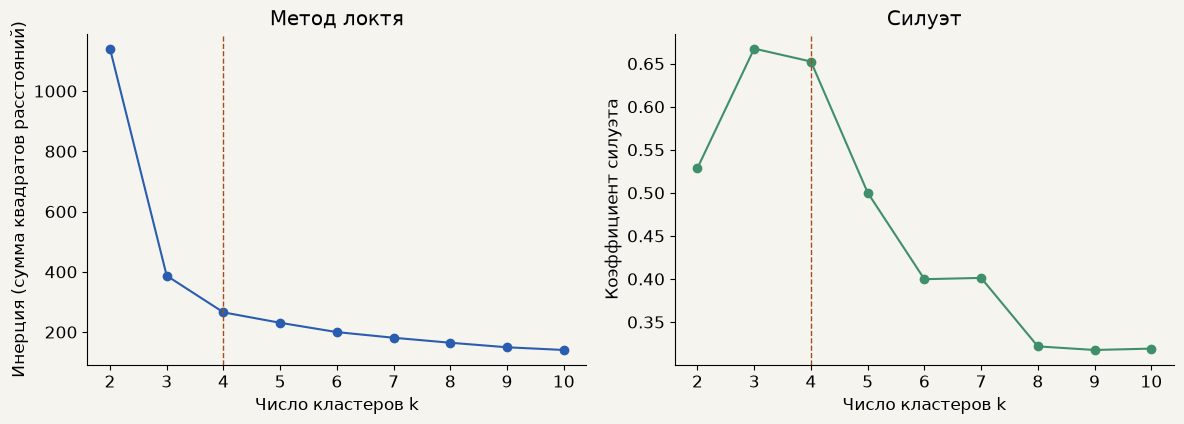

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(list(ks), inertia, "o-", color=COLORS[1])
axes[0].set_xlabel("Число кластеров k"); axes[0].set_ylabel("Инерция (сумма квадратов расстояний)")
axes[0].set_title("Метод локтя")
axes[0].axvline(4, color=COLORS[0], ls="--", lw=1)

axes[1].plot(list(ks), sil, "o-", color=COLORS[2])
axes[1].set_xlabel("Число кластеров k"); axes[1].set_ylabel("Коэффициент силуэта")
axes[1].set_title("Силуэт")
axes[1].axvline(4, color=COLORS[0], ls="--", lw=1)
fig.tight_layout(); fig.savefig("figs/pr10_B_elbow_silhouette.png", dpi=160)
plt.show()

**Что видно на графиках:**
- **Локоть.** С k = 2 до k = 3 инерция падает очень сильно (1141 → 387), с 3 до 4 — ещё заметно (387 → 265). Дальше падение маленькое (265 → 231 → 200 …). Значит, «локоть» находится в районе k = 3–4, а после 4 новые кластеры почти ничего не дают.
- **Силуэт.** Максимум при k = 3 (0.667), но при k = 4 почти столько же (0.652). С k = 5 силуэт резко падает (0.500 и ниже): кластеры начинают делиться искусственно.

Оба критерия говорят: k = 3 или k = 4. Чтобы выбрать, сравниваю профили при k = 3 и k = 4.

In [7]:
for k in (3, 4):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    prof = df.groupby(lab)[features].mean().round(2)
    prof["clients"] = np.bincount(lab)
    print(f"k = {k}"); print(prof, end="\n\n")

k = 3
   avg_check  purchases_month  days_since_last  discount_share  clients
0    5175.85             2.78            20.62            0.14      210
1     884.42             6.94             6.14            0.59      220
2    1543.98             0.70            91.95            0.33      170

k = 4
   avg_check  purchases_month  days_since_last  discount_share  clients
0    5037.63             6.15             3.78            0.09       59
1     884.42             6.94             6.14            0.59      220
2    1543.98             0.70            91.95            0.33      170
3    5229.86             1.47            27.21            0.16      151



**Выбор: k = 4.**

При k = 3 все клиенты с большим чеком (~5000 сом) попадают в один кластер, хотя внутри него две разные группы. Одни покупают ~6 раз в месяц и были пару дней назад. Другие покупают ~1.5 раза в месяц и не приходили почти месяц. Для магазина это разные клиенты: первых нужно удерживать, вторых — стимулировать покупать чаще. При k = 4 они разделяются.

Силуэт при k = 4 почти такой же, как при k = 3 (0.652 против 0.667), и это всё ещё точка локтя. Значит, качество разбиения почти не теряется, а практической пользы больше. При k = 5 силуэт падает до 0.5: кластер «скидочников» просто режется на две части по частоте покупок, нового смысла это не даёт.

## Шаг 4. Итоговая модель (k = 4) и профили кластеров

In [8]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X)

profile = df.groupby("cluster")[features].mean().round(2)
profile["clients"] = df["cluster"].value_counts().sort_index()
profile["доля, %"] = (profile["clients"] / len(df) * 100).round(1)
print(profile)

         avg_check  purchases_month  days_since_last  discount_share  clients  \
cluster                                                                         
0          5037.63             6.15             3.78            0.09       59   
1           884.42             6.94             6.14            0.59      220   
2          1543.98             0.70            91.95            0.33      170   
3          5229.86             1.47            27.21            0.16      151   

         доля, %  
cluster           
0            9.8  
1           36.7  
2           28.3  
3           25.2  


In [9]:
# Во сколько раз признак в кластере больше/меньше среднего по всем клиентам
print((df.groupby("cluster")[features].mean() / df[features].mean()).round(2))

         avg_check  purchases_month  days_since_last  discount_share
cluster                                                             
0             1.96             1.65             0.11            0.25
1             0.34             1.87             0.17            1.64
2             0.60             0.19             2.59            0.92
3             2.03             0.40             0.77            0.44


In [10]:
names = {0: "VIP-клиенты",
         1: "Охотники за скидками",
         2: "Спящие (уходящие)",
         3: "Редкие крупные покупатели"}
profile.insert(0, "название", profile.index.map(names))
print(profile.to_string())

                          название  avg_check  purchases_month  days_since_last  discount_share  clients  доля, %
cluster                                                                                                          
0                      VIP-клиенты    5037.63             6.15             3.78            0.09       59      9.8
1             Охотники за скидками     884.42             6.94             6.14            0.59      220     36.7
2                Спящие (уходящие)    1543.98             0.70            91.95            0.33      170     28.3
3        Редкие крупные покупатели    5229.86             1.47            27.21            0.16      151     25.2


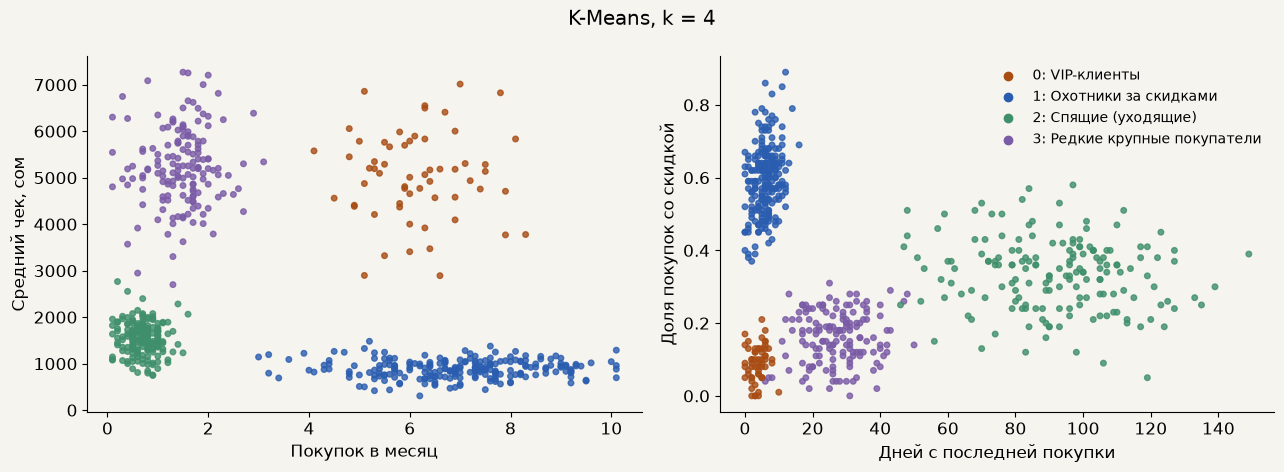

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(df["purchases_month"], df["avg_check"], c=COLORS[df["cluster"]], s=16, alpha=0.8)
axes[0].set_xlabel("Покупок в месяц"); axes[0].set_ylabel("Средний чек, сом")
axes[1].scatter(df["days_since_last"], df["discount_share"], c=COLORS[df["cluster"]], s=16, alpha=0.8)
axes[1].set_xlabel("Дней с последней покупки"); axes[1].set_ylabel("Доля покупок со скидкой")
for c in range(4):
    axes[1].scatter([], [], c=COLORS[c], label=f"{c}: {names[c]}")
axes[1].legend(frameon=False, fontsize=10)
fig.suptitle("K-Means, k = 4")
fig.tight_layout(); fig.savefig("figs/pr10_B_clusters.png", dpi=160)
plt.show()

**Описание сегментов:**

| № | Название | Чем отличается |
|---|---|---|
| 0 | **VIP-клиенты** (59 чел., ~10%) | Высокий чек ~5040 сом, покупают ~6 раз в месяц, последняя покупка ~4 дня назад, скидками почти не пользуются (9%). Самые ценные клиенты. |
| 1 | **Охотники за скидками** (220 чел., ~37%) | Самый маленький чек ~880 сом, но покупают чаще всех (~7 раз в месяц), 59% покупок — по скидке. Активные, но приносят мало с одной покупки. |
| 2 | **Спящие (уходящие)** (170 чел., ~28%) | Чек ~1540 сом, покупают меньше раза в месяц (0.7) и не приходили в среднем ~92 дня. Группа риска оттока. |
| 3 | **Редкие крупные покупатели** (151 чел., ~25%) | Высокий чек ~5230 сом, но покупают редко (~1.5 раза в месяц), последняя покупка ~27 дней назад, скидки берут мало (16%). |

**Что можно делать с сегментами:**
- VIP — программа лояльности, персональный сервис, без лишних скидок (они им не нужны);
- охотники за скидками — акции, купоны, «купи больше — получи скидку», чтобы поднять чек;
- спящие — рассылка «мы скучаем», персональное предложение для возврата;
- редкие крупные — напоминания и новинки, чтобы приходили чаще.

## Шаг 5. Устойчивость результата
Повторяю кластеризацию с другими `random_state` и сравниваю с основной моделью (random_state = 42). Номера кластеров могут поменяться местами, поэтому сравниваю не номера, а состав. Для этого использую:
- `adjusted_rand_score` (ARI): 1 — разбиения совпадают полностью, около 0 — совпадение случайное;
- таблицу сопряжённости: если в каждой строке только одно ненулевое число, состав кластеров тот же.

In [12]:
for rs in [0, 7, 123, 2024]:
    other = KMeans(n_clusters=4, n_init=10, random_state=rs).fit(X)
    ari = adjusted_rand_score(df["cluster"], other.labels_)
    print(f"random_state = {rs:4d} | ARI = {ari:.3f} | инерция = {other.inertia_:.1f}")

random_state =    0 | ARI = 1.000 | инерция = 265.4
random_state =    7 | ARI = 1.000 | инерция = 265.4


random_state =  123 | ARI = 1.000 | инерция = 265.4
random_state = 2024 | ARI = 1.000 | инерция = 265.4


In [13]:
other = KMeans(n_clusters=4, n_init=10, random_state=123).fit_predict(X)
print("Строки — кластеры при random_state=42, столбцы — при random_state=123")
print(pd.crosstab(df["cluster"], other, rownames=["rs=42"], colnames=["rs=123"]))

Строки — кластеры при random_state=42, столбцы — при random_state=123
rs=123    0    1    2   3
rs=42                    
0         0    0    0  59
1         0  220    0   0
2         0    0  170   0
3       151    0    0   0


In [14]:
# Более жёсткая проверка: только одна инициализация (n_init=1)
aris = [adjusted_rand_score(df["cluster"], KMeans(n_clusters=4, n_init=1, random_state=rs).fit_predict(X))
        for rs in range(20)]
print("ARI при n_init=1 для 20 разных random_state:", np.round(aris, 3))
print("Полностью совпали:", sum(a > 0.999 for a in aris), "из 20")

ARI при n_init=1 для 20 разных random_state: [1.    1.    1.    1.    0.716 1.    1.    1.    1.    0.788 1.    0.783
 1.    1.    0.712 1.    1.    0.788 1.    1.   ]
Полностью совпали: 15 из 20


**Вывод по устойчивости:** при всех других `random_state` ARI = 1.0, а инерция та же. Состав кластеров **не изменился**, поменялась только нумерация: например, при random_state = 123 кластер «Редкие крупные» получил номер 0 вместо 3. Значит, сегменты устойчивые и не зависят от случайного начального положения центров. Это связано с тем, что группы в данных хорошо отделены друг от друга.

Если оставить только одну инициализацию (`n_init=1`), то в 5 случаях из 20 получилось другое разбиение (ARI ≈ 0.7–0.8). K-Means может застрять в локальном минимуме. Поэтому `n_init=10` нужен: из 10 запусков выбирается лучший.

## Итоговый вывод
1. Признаки отмасштабированы `StandardScaler`, иначе всё решал бы средний чек.
2. Метод локтя показывает изгиб на k = 3–4, силуэт максимален при k = 3 (0.667), при k = 4 почти столько же (0.652).
3. Выбрано **k = 4**: только при нём частые и редкие покупатели с большим чеком разделяются. Для магазина это разные группы с разной стратегией.
4. Сегменты: **VIP-клиенты**, **Охотники за скидками**, **Спящие**, **Редкие крупные покупатели**.
5. Результат устойчив: при других `random_state` состав кластеров тот же (ARI = 1.0).